# Assignment 2: training pipeline

You're using a notebook for this stage. If you'd rather use a script,
write `train.py` instead and delete this file. `main.py` refuses to run if
it finds both `train.py` and `train.ipynb`, so exactly one of them must exist.

Replace this cell and everything below it with your own code. When run
via `uv run python main.py train`, this notebook must, start to finish, with no
manual steps in between:

- Get your Roboflow API key via `from api_key import load_api_key`, so that it
  works whether the key is in your `.env` file or in the environment, and
  download your dataset version from Roboflow Universe.
- Finetune yolo11n/yolo11s (or the -cls variant) on that dataset, from the
  pretrained checkpoint.
- Evaluate on the test split against the two baselines named in the brief: the
  pretrained COCO model zero-shot, and a trivial predict-nothing / majority
  class baseline.
- Sweep the confidence threshold, compute the expected cost at each point from
  the cost matrix you defined in REPORT.md, and save the sweep.
- Save everything `app.py` needs to build its dashboard without retraining:
  the metrics, the per-class numbers, the cost sweep, and the chosen operating
  point.

This is your real training pipeline. It takes as long as it takes, and it runs
wherever training is practical for you: your own machine, a GPU you have access
to, or a hosted notebook. Nothing re-runs it to check your submission.

The weights it produces are what you commit to `weights/` and what your app
serves. Say in REPORT.md where you trained and what settings you used.

Save the trained model into `weights/`. That is the file you commit and the
file your app loads.

How you structure the code beyond that is your call to make and be able to
defend: file layout, function boundaries, naming.


# Asphalt Distress Detection — YOLO11

## 1. Dataset Exploration

This project uses the Asphalt Distress Detection dataset from Roboflow Universe, version 2.

Before training YOLO11, I will explore the number of images, class distribution, bounding-box sizes, and example annotations to understand the dataset's strengths and limitations.

In [3]:
from pathlib import Path
from IPython.display import display
import yaml
import shutil

# Project folders
ROOT = Path.cwd()
DATA = ROOT / "data" / "asphalt"
ARTIFACTS = ROOT / "artifacts"
WEIGHTS = ROOT / "weights"

ARTIFACTS.mkdir(exist_ok=True)
WEIGHTS.mkdir(exist_ok=True)

# Expected dataset sizes
expected = {
    "train": 2200,
    "valid": 628,
    "test": 316
}

def dataset_ready():
    if not (DATA / "data.yaml").exists():
        return False

    for split, expected_count in expected.items():
        images_folder = DATA / split / "images"
        labels_folder = DATA / split / "labels"

        if not images_folder.is_dir() or not labels_folder.is_dir():
            return False

        images = [
            p for p in images_folder.iterdir()
            if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
        ]

        if len(images) != expected_count:
            return False

        if len(list(labels_folder.glob("*.txt"))) != expected_count:
            return False

    return True


# Download automatically if missing or incomplete
if not dataset_ready():
    from roboflow import Roboflow
    from api_key import load_api_key

    if DATA.exists():
        shutil.rmtree(DATA)

    rf = Roboflow(api_key=load_api_key())

    dataset = (
        rf.workspace("roboflow100vl-full")
        .project("asphaltdistressdetection-shlk")
        .version(2)
        .download("yolov11", location=str(DATA))
    )

if not dataset_ready():
    raise RuntimeError("Dataset download is incomplete.")

# Configure dataset paths for YOLO
with open(DATA / "data.yaml") as f:
    config = yaml.safe_load(f)

config["path"] = str(DATA.resolve())
config["train"] = "train/images"
config["val"] = "valid/images"
config["test"] = "test/images"

EVAL_YAML = ARTIFACTS / "asphalt_eval.yaml"

with open(EVAL_YAML, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("Dataset ready!")
print("Training images:", expected["train"])
print("Validation images:", expected["valid"])
print("Test images:", expected["test"])
print("Configuration:", EVAL_YAML)

Dataset ready!
Training images: 2200
Validation images: 628
Test images: 316
Configuration: /workspaces/daiist-assignment-2/artifacts/asphalt_eval.yaml


In [4]:
from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt

class_names = [
    "Alligator crack",
    "Longitudinal crack",
    "Oblique crack",
    "Pothole",
    "Repair",
    "Transverse crack"
]

splits = ["train", "valid", "test"]

class_counts = {}
box_areas = {}

for split in splits:
    images_folder = DATA / split / "images"
    labels_folder = DATA / split / "labels"

    images = list(images_folder.glob("*.jpg"))
    labels = list(labels_folder.glob("*.txt"))

    counts = Counter()
    areas = []

    for label_file in labels:
        with open(label_file, "r") as f:
            for line in f:
                if not line.strip():
                    continue

                values = list(map(float, line.split()))
                class_id, x, y, w, h = values

                counts[int(class_id)] += 1
                areas.append(w * h)

    class_counts[split] = counts
    box_areas[split] = areas

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Annotated objects:", sum(counts.values()))

    for i, name in enumerate(class_names):
        print(f"{name}: {counts[i]}")


TRAIN
Images: 2200
Annotated objects: 3478
Alligator crack: 297
Longitudinal crack: 911
Oblique crack: 131
Pothole: 63
Repair: 1157
Transverse crack: 919

VALID
Images: 628
Annotated objects: 987
Alligator crack: 79
Longitudinal crack: 288
Oblique crack: 30
Pothole: 21
Repair: 311
Transverse crack: 258

TEST
Images: 316
Annotated objects: 504
Alligator crack: 38
Longitudinal crack: 140
Oblique crack: 12
Pothole: 10
Repair: 154
Transverse crack: 150


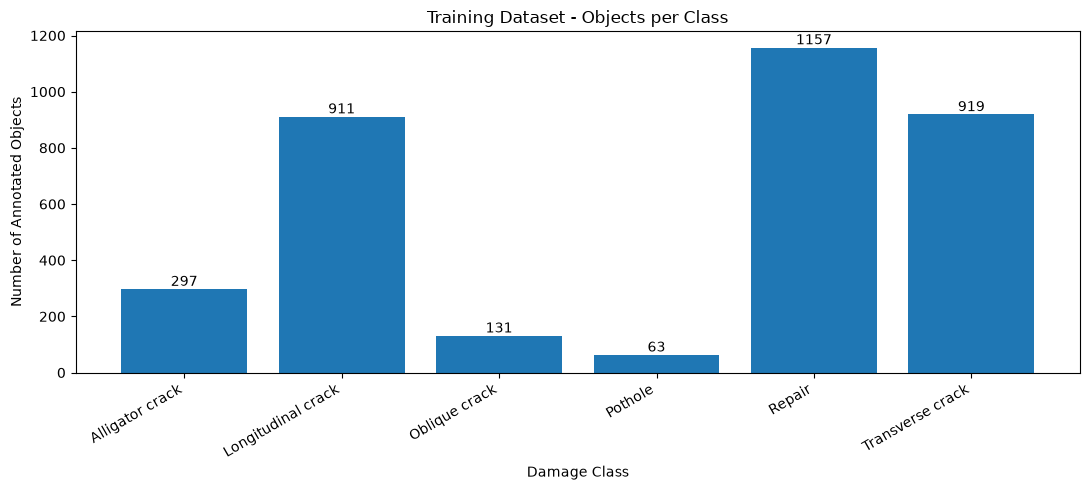

In [5]:
fig, ax = plt.subplots(figsize=(11, 5))

train_counts = [
    class_counts["train"][i]
    for i in range(len(class_names))
]

bars = ax.bar(class_names, train_counts)

ax.set_title("Training Dataset - Objects per Class")
ax.set_xlabel("Damage Class")
ax.set_ylabel("Number of Annotated Objects")

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        str(int(height)),
        ha="center",
        va="bottom"
    )

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Number of boxes: 3478
Average relative box area: 0.0783
Median relative box area: 0.0395
Smallest relative box area: 0.000839
Largest relative box area: 0.714


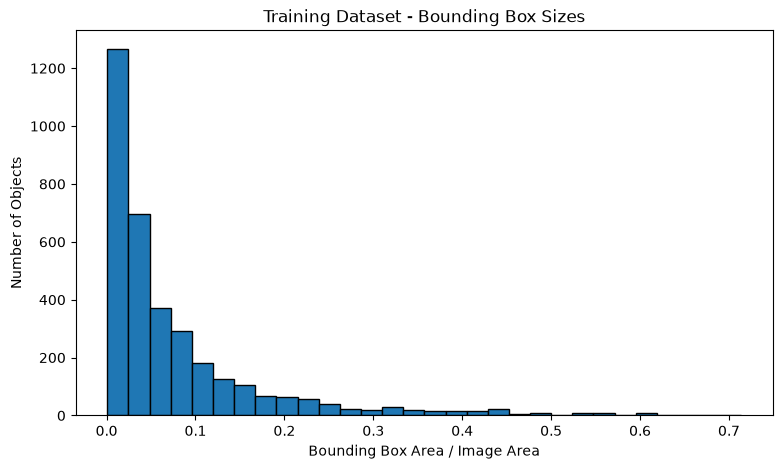

In [6]:
import numpy as np

train_areas = np.array(box_areas["train"])

print("Number of boxes:", len(train_areas))
print("Average relative box area:", round(train_areas.mean(), 4))
print("Median relative box area:", round(np.median(train_areas), 4))
print("Smallest relative box area:", round(train_areas.min(), 6))
print("Largest relative box area:", round(train_areas.max(), 4))

plt.figure(figsize=(9, 5))
plt.hist(train_areas, bins=30, edgecolor="black")

plt.title("Training Dataset - Bounding Box Sizes")
plt.xlabel("Bounding Box Area / Image Area")
plt.ylabel("Number of Objects")
plt.show()

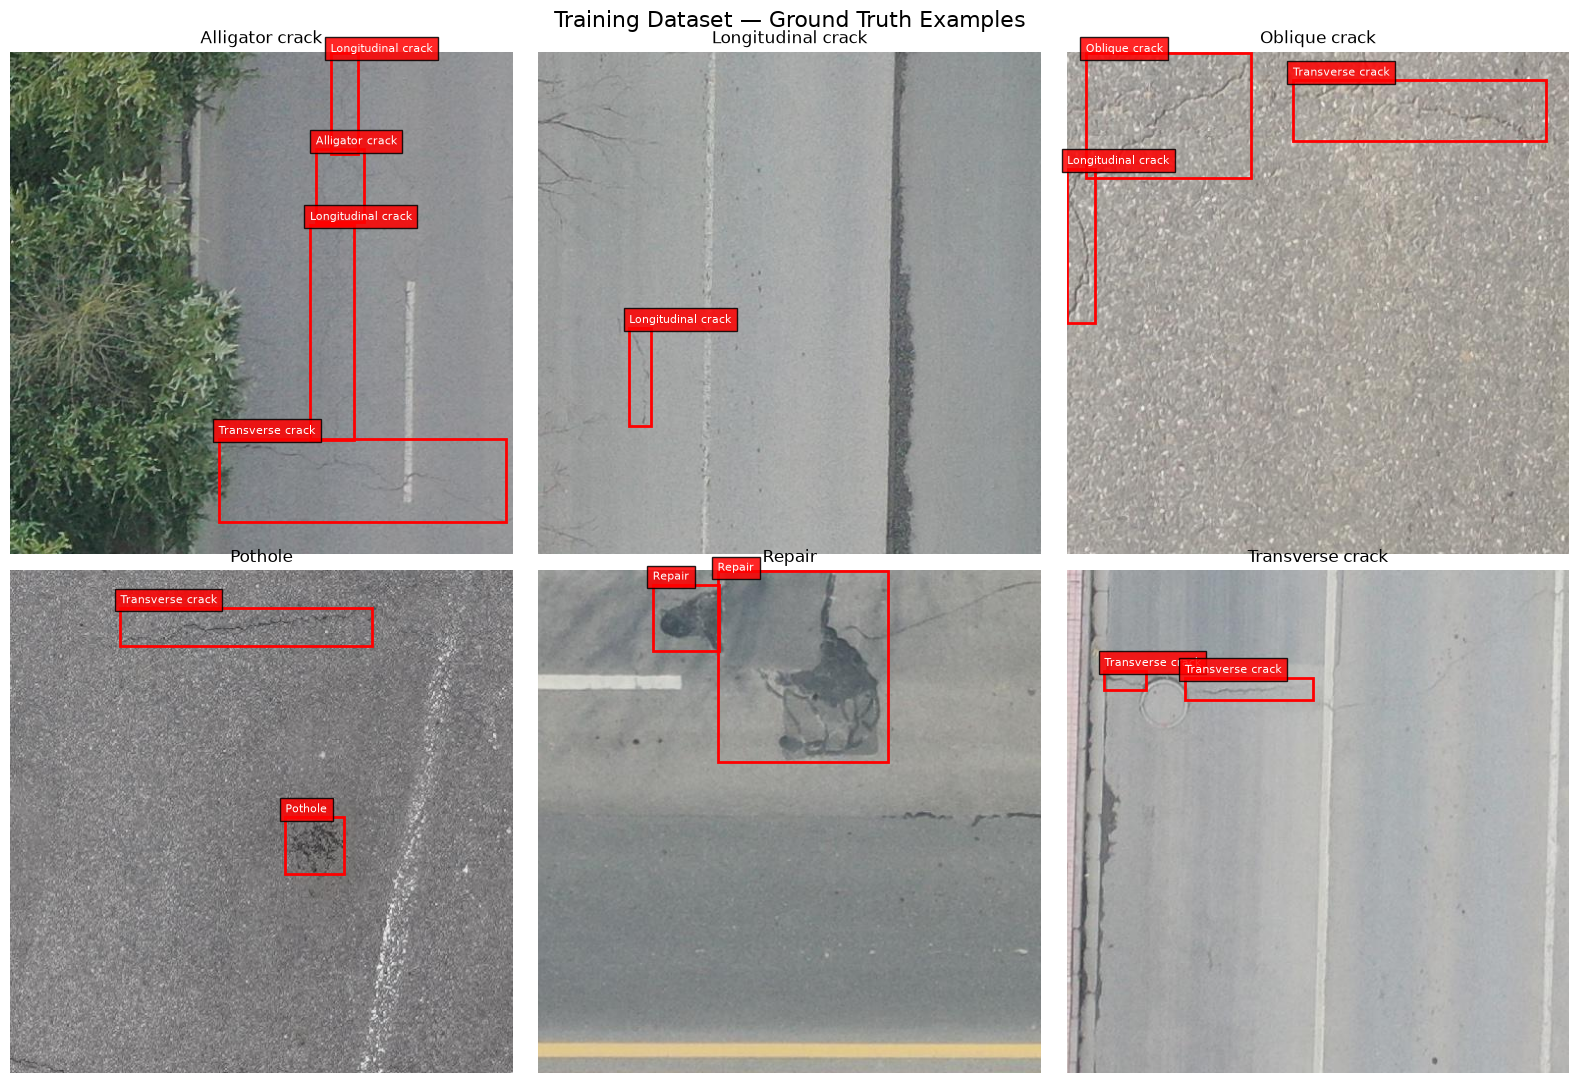

In [7]:
from pathlib import Path
from PIL import Image
from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt
import random

DATA = Path("data/asphalt")

class_names = [
    "Alligator crack",
    "Longitudinal crack",
    "Oblique crack",
    "Pothole",
    "Repair",
    "Transverse crack"
]

images_folder = DATA / "train/images"
labels_folder = DATA / "train/labels"

# Shuffle files to select reproducible examples
label_files = sorted(labels_folder.glob("*.txt"))
random.Random(42).shuffle(label_files)

examples = {}
used_images = set()

# Find a different image containing each class
for class_id in range(len(class_names)):
    for label_file in label_files:

        if label_file.stem in used_images:
            continue

        annotations = [
            line.split()
            for line in label_file.read_text().splitlines()
            if line.strip()
        ]

        if not any(int(row[0]) == class_id for row in annotations):
            continue

        image_path = next(
            (
                p for p in images_folder.glob(label_file.stem + ".*")
                if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
            ),
            None
        )

        if image_path is not None:
            examples[class_id] = (image_path, annotations)
            used_images.add(label_file.stem)
            break

# Display examples in a 2 x 3 grid
fig, axes = plt.subplots(2, 3, figsize=(16, 11))

for class_id, ax in enumerate(axes.flat):

    if class_id not in examples:
        ax.set_title(f"No example: {class_names[class_id]}")
        ax.axis("off")
        continue

    image_path, annotations = examples[class_id]

    with Image.open(image_path) as img:
        image = img.copy()

    width, height = image.size
    ax.imshow(image)

    # Draw all ground-truth boxes
    for row in annotations:
        cls = int(row[0])
        xc, yc, w, h = map(float, row[1:5])

        x = (xc - w / 2) * width
        y = (yc - h / 2) * height

        box_width = w * width
        box_height = h * height

        ax.add_patch(Rectangle(
            (x, y),
            box_width,
            box_height,
            fill=False,
            edgecolor="red",
            linewidth=2
        ))

        ax.text(
            x, max(0, y - 5),
            class_names[cls],
            color="white",
            fontsize=8,
            bbox=dict(facecolor="red", alpha=0.85)
        )

    ax.set_title(class_names[class_id], fontsize=12)
    ax.axis("off")

plt.suptitle(
    "Training Dataset — Ground Truth Examples",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [9]:
from ultralytics import YOLO
import torch
import shutil
import os

# Use saved weights only when explicitly requested
USE_SAVED_MODEL = os.getenv("ASPHALT_USE_SAVED", "0") == "1"

model_path = WEIGHTS / "best.pt"
results_path = ARTIFACTS / "asphalt_yolo11n_results.csv"

if USE_SAVED_MODEL:

    if not model_path.exists() or not results_path.exists():
        raise FileNotFoundError(
            "Saved model or training results are missing."
        )

    print("Using existing Colab-trained model.")
    print("No training performed.")

else:

    # Full training pipeline
    DEVICE = 0 if torch.cuda.is_available() else "cpu"
    print("Training on:", DEVICE)

    model = YOLO("yolo11n.pt")

    model.train(
        data=str(EVAL_YAML.resolve()),
        epochs=30,
        imgsz=640,
        batch=16,
        device=DEVICE,
        seed=42,
        project=str((ARTIFACTS / "training_runs").resolve()),
        name="asphalt_yolo11n",
        exist_ok=True
    )

    run_folder = Path(model.trainer.save_dir)

    shutil.copy2(
        run_folder / "weights" / "best.pt",
        model_path
    )

    shutil.copy2(
        run_folder / "results.csv",
        results_path
    )

    print("Training completed and files saved.")

# Load final model
model = YOLO(str(model_path))

print("Model ready:", model_path)

Using existing Colab-trained model.
No training performed.
Model ready: /workspaces/daiist-assignment-2/weights/best.pt


## 2. YOLO11 Training Results

I fine-tuned a pretrained YOLO11n model for 30 epochs using a Tesla T4 GPU in Google Colab. The following graphs show how the model's performance changed during training.

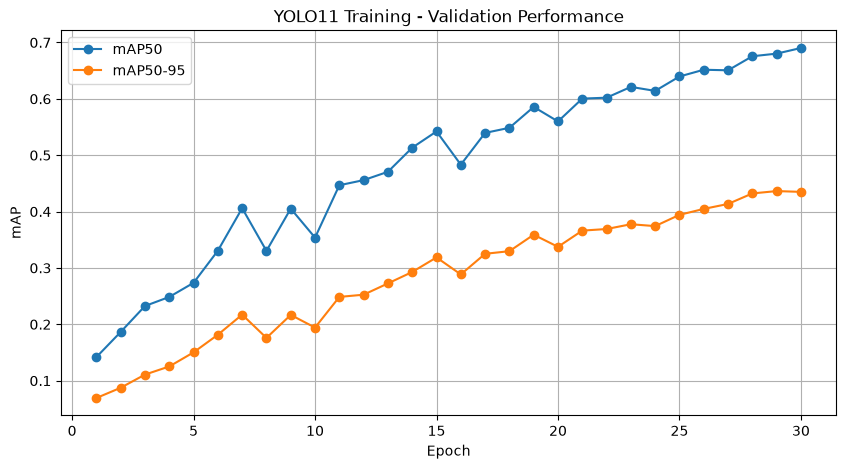

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.read_csv(
    "artifacts/asphalt_yolo11n_results.csv"
)

plt.figure(figsize=(10, 5))

plt.plot(
    results["epoch"],
    results["metrics/mAP50(B)"],
    label="mAP50",
    marker="o"
)

plt.plot(
    results["epoch"],
    results["metrics/mAP50-95(B)"],
    label="mAP50-95",
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("mAP")
plt.title("YOLO11 Training - Validation Performance")
plt.legend()
plt.grid(True)
plt.show()

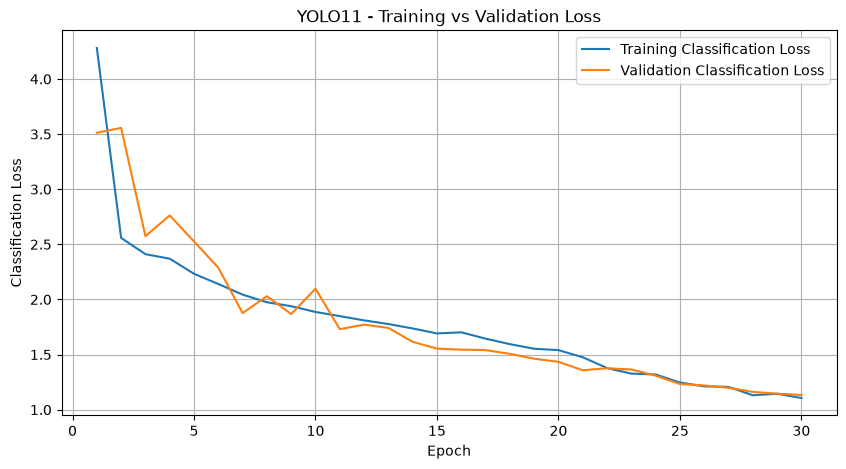

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(
    results["epoch"],
    results["train/cls_loss"],
    label="Training Classification Loss"
)

plt.plot(
    results["epoch"],
    results["val/cls_loss"],
    label="Validation Classification Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Classification Loss")
plt.title("YOLO11 - Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

## 3. Fine-Tuned vs Scratch Model Comparison

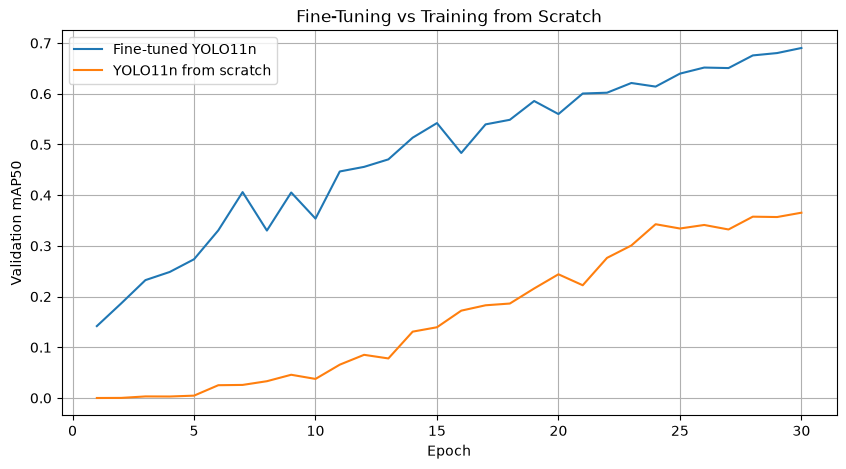

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

fine = pd.read_csv(ARTIFACTS / "asphalt_yolo11n_results.csv")
scratch_path = ARTIFACTS / "scratch_results.csv"

if scratch_path.is_file():
    scratch = pd.read_csv(scratch_path)
    plt.figure(figsize=(10, 5))
    plt.plot(fine["epoch"], fine["metrics/mAP50(B)"], label="Fine-tuned YOLO11n")
    plt.plot(scratch["epoch"], scratch["metrics/mAP50(B)"], label="YOLO11n from scratch")
    plt.xlabel("Epoch")
    plt.ylabel("Validation mAP50")
    plt.title("Fine-Tuning vs Training from Scratch")
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print("Optional scratch history not present; scratch comparison plot skipped.")

## 4. Baseline Models

### 4.1 Predict-Nothing Baseline

This baseline predicts no objects in any image. It provides a simple reference for evaluating whether training YOLO11 produces meaningful improvements.

In [13]:
# Predict-nothing baseline

# Number of actual objects in validation
total_objects = sum(class_counts["valid"].values())

# This baseline never predicts any bounding boxes
true_positives = 0
false_positives = 0
false_negatives = total_objects

precision = 0.0
recall = 0.0
map50 = 0.0
map50_95 = 0.0

print("PREDICT-NOTHING BASELINE")
print("Actual objects:", total_objects)
print("True positives:", true_positives)
print("False positives:", false_positives)
print("False negatives:", false_negatives)
print("Precision:", precision)
print("Recall:", recall)
print("mAP50:", map50)
print("mAP50-95:", map50_95)

PREDICT-NOTHING BASELINE
Actual objects: 987
True positives: 0
False positives: 0
False negatives: 987
Precision: 0.0
Recall: 0.0
mAP50: 0.0
mAP50-95: 0.0


### 4.2 COCO Zero-Shot Baseline

This experiment tests the original COCO-pretrained YOLO11n model on asphalt images without fine-tuning its weights.

Alligator crack - COCO detections: 0
Longitudinal crack - COCO detections: 0
Oblique crack - COCO detections: 0
Pothole - COCO detections: 0
Repair - COCO detections: 1
Transverse crack - COCO detections: 0


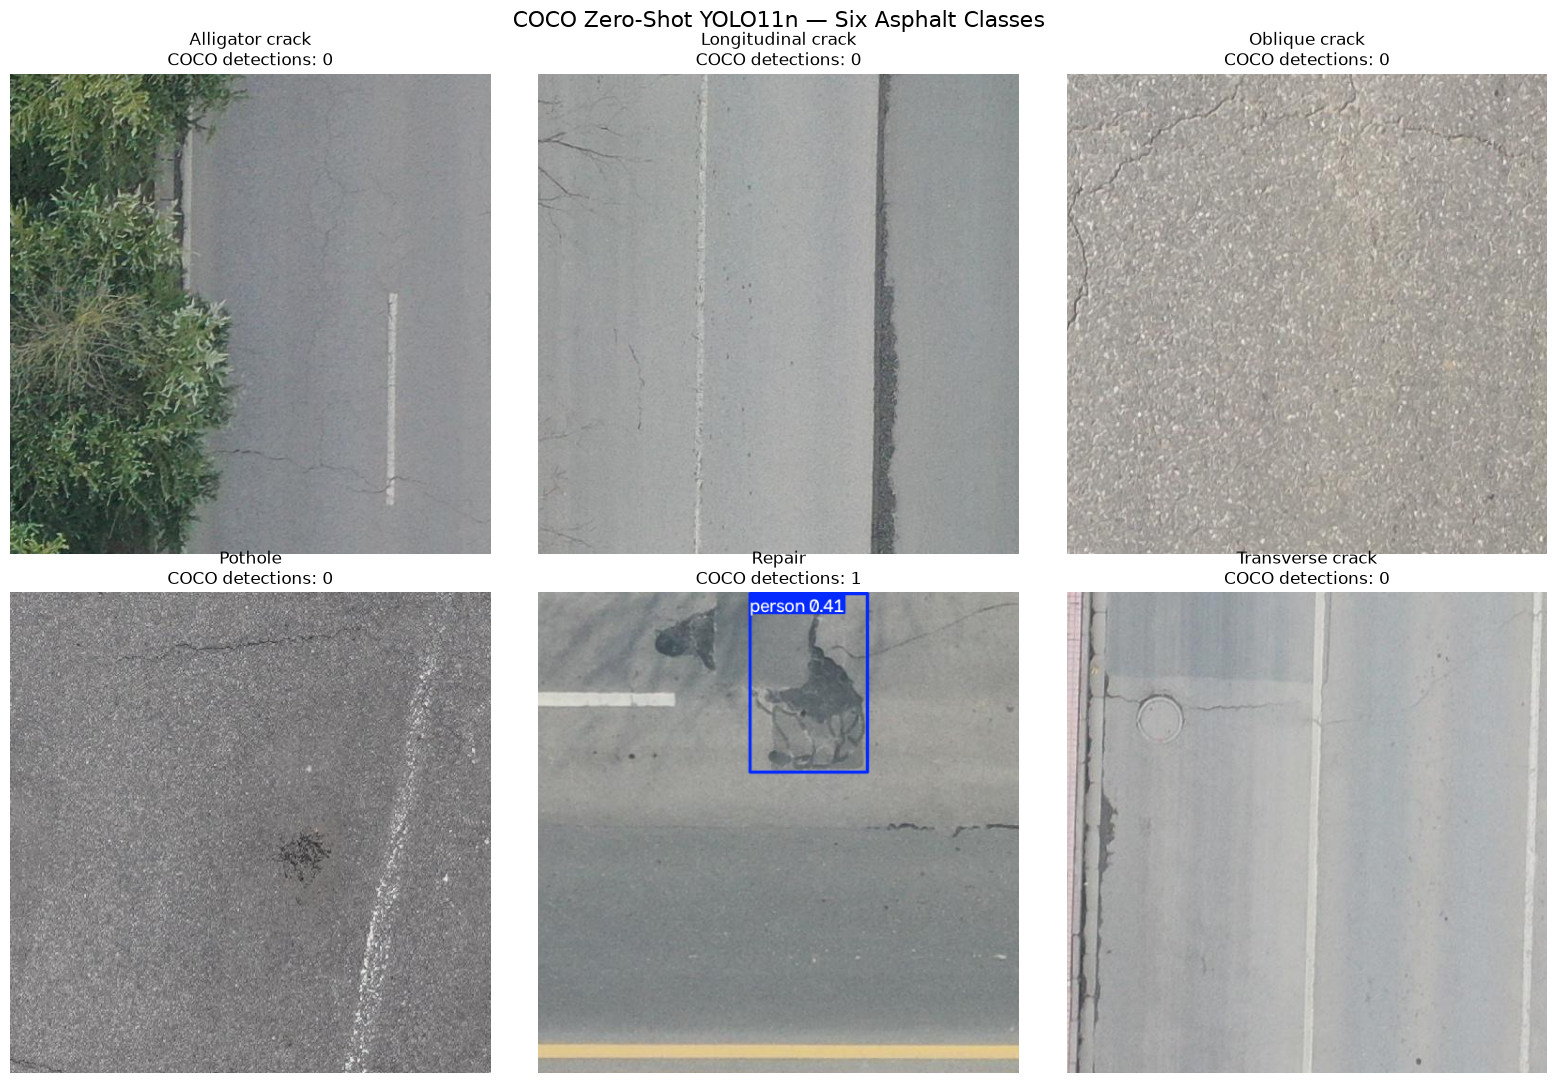


Total COCO detections: 1


In [15]:
from ultralytics import YOLO
import matplotlib.pyplot as plt

# Load original COCO-pretrained model
coco_model = YOLO("yolo11n.pt")

fig, axes = plt.subplots(2, 3, figsize=(16, 11))

total_detections = 0

for class_id, ax in enumerate(axes.flat):

    # Reuse the six examples selected earlier
    sample_path, _ = examples[class_id]

    prediction = coco_model.predict(
        source=str(sample_path),
        conf=0.25,
        imgsz=640,
        device="cpu",
        verbose=False
    )[0]

    num_detections = len(prediction.boxes)
    total_detections += num_detections

    # YOLO returns BGR images; convert to RGB
    annotated_image = prediction.plot()[:, :, ::-1]

    ax.imshow(annotated_image)
    ax.set_title(
        f"{class_names[class_id]}\n"
        f"COCO detections: {num_detections}"
    )
    ax.axis("off")

    print(
        class_names[class_id],
        "- COCO detections:",
        num_detections
    )

plt.suptitle(
    "COCO Zero-Shot YOLO11n — Six Asphalt Classes",
    fontsize=16
)

plt.tight_layout()
plt.show()

print("\nTotal COCO detections:", total_detections)

### 4.3 Fine-Tuned YOLO11n Predictions

Alligator crack - Fine-tuned detections: 3
Longitudinal crack - Fine-tuned detections: 1
Oblique crack - Fine-tuned detections: 2
Pothole - Fine-tuned detections: 2
Repair - Fine-tuned detections: 5
Transverse crack - Fine-tuned detections: 3


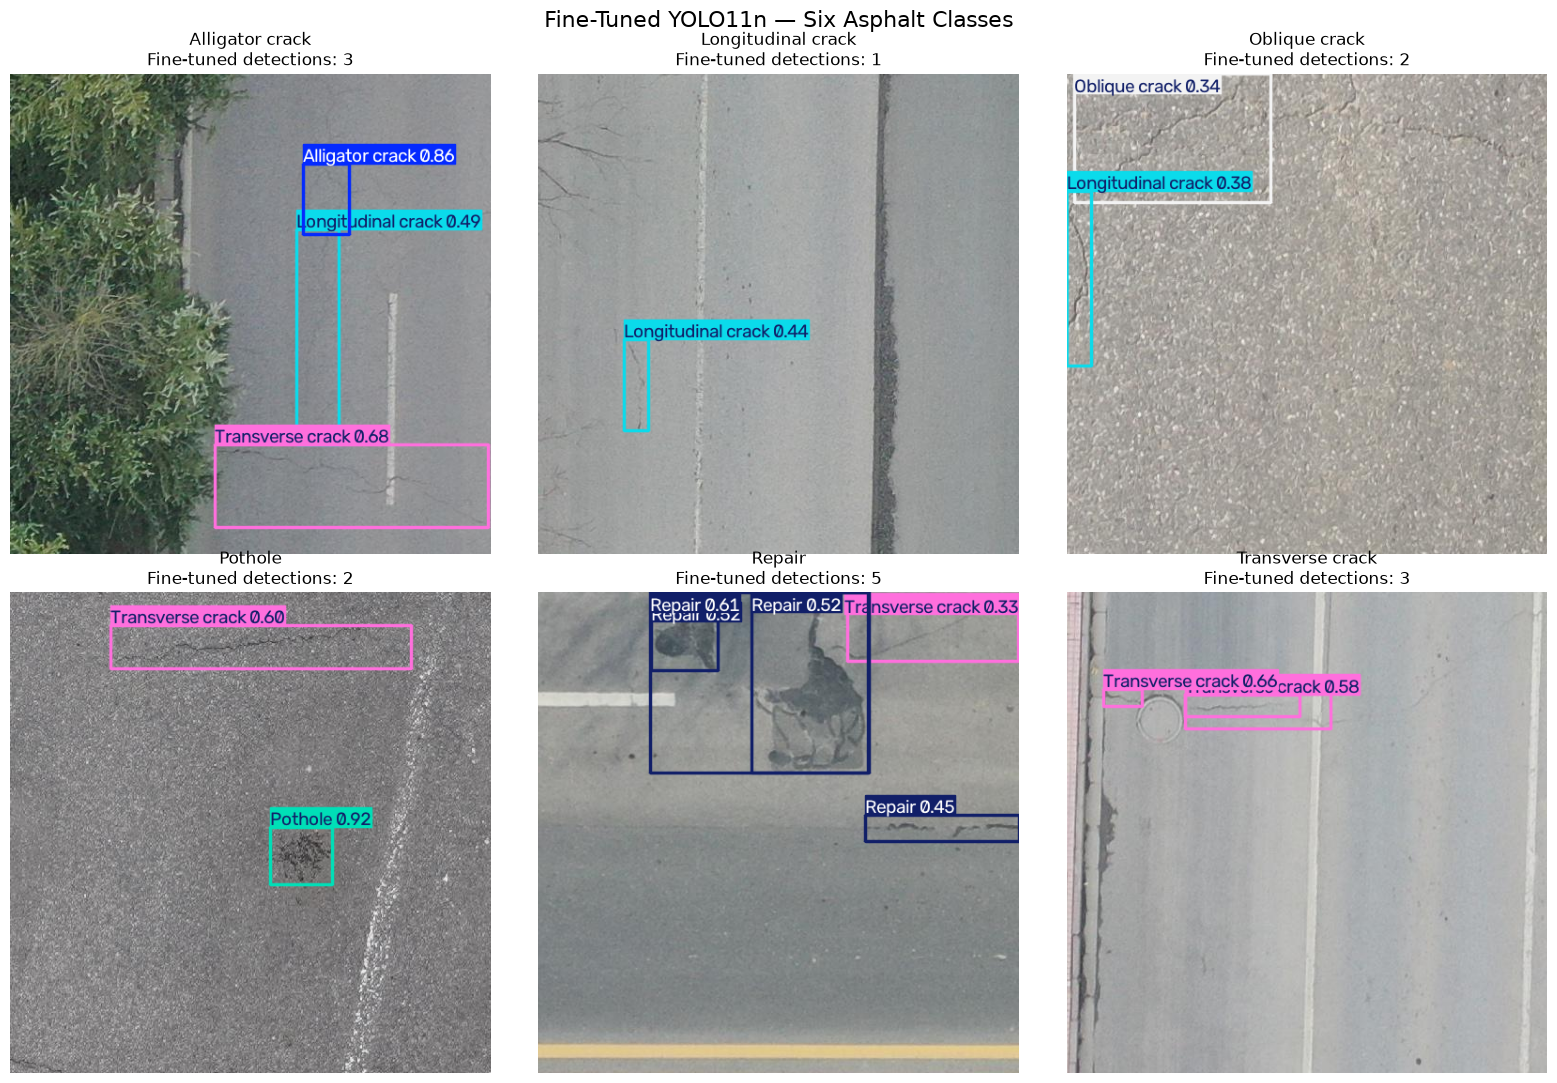


Total fine-tuned detections: 16


In [16]:
from ultralytics import YOLO
import matplotlib.pyplot as plt

# Load our fine-tuned model
fine_model = YOLO(str(WEIGHTS / "best.pt"))

fig, axes = plt.subplots(2, 3, figsize=(16, 11))

total_detections = 0

for class_id, ax in enumerate(axes.flat):

    # Use exactly the same images as the COCO baseline
    sample_path, _ = examples[class_id]

    prediction = fine_model.predict(
        source=str(sample_path),
        conf=0.25,
        imgsz=640,
        device="cpu",
        verbose=False
    )[0]

    num_detections = len(prediction.boxes)
    total_detections += num_detections

    annotated_image = prediction.plot()[:, :, ::-1]

    ax.imshow(annotated_image)
    ax.set_title(
        f"{class_names[class_id]}\n"
        f"Fine-tuned detections: {num_detections}"
    )
    ax.axis("off")

    print(
        class_names[class_id],
        "- Fine-tuned detections:",
        num_detections
    )

plt.suptitle(
    "Fine-Tuned YOLO11n — Six Asphalt Classes",
    fontsize=16
)

plt.tight_layout()
plt.show()

print("\nTotal fine-tuned detections:", total_detections)

## 5. Detailed Model Evaluation

In [17]:
from ultralytics import YOLO

# Load the model trained in Google Colab
model = YOLO(str(WEIGHTS / "best.pt"))

# Evaluate on the validation dataset
metrics = model.val(
    data=str(EVAL_YAML.resolve()),
    split="val",
    imgsz=640,
    batch=8,
    device="cpu",
    plots=True,
    project=str(ARTIFACTS / "validation"),
    name="fine_tuned",
    exist_ok=True
)

print("Validation mAP50:", round(metrics.box.map50, 4))
print("Validation mAP50-95:", round(metrics.box.map, 4))
print("Results saved to:", metrics.save_dir)

Ultralytics 8.4.173 🚀 Python-3.12.3 torch-2.11.0+cpu CPU (Intel Xeon Platinum 8370C CPU @ 2.80GHz)
YOLO11n summary (fused): 101 layers, 2,598,266 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 15.0±6.5 MB/s, size: 32.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /workspaces/daiist-assignment-2/data/asphalt/valid/labels.cache... 628 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 628/628 90.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 79/79 1.5s/it 1:561.4sss
                   all        628        987      0.741      0.575       0.68      0.437
       Alligator crack         69         79       0.86      0.582      0.681      0.454
    Longitudinal crack        225        288      0.794       0.58      0.747      0.399
         Oblique crack 

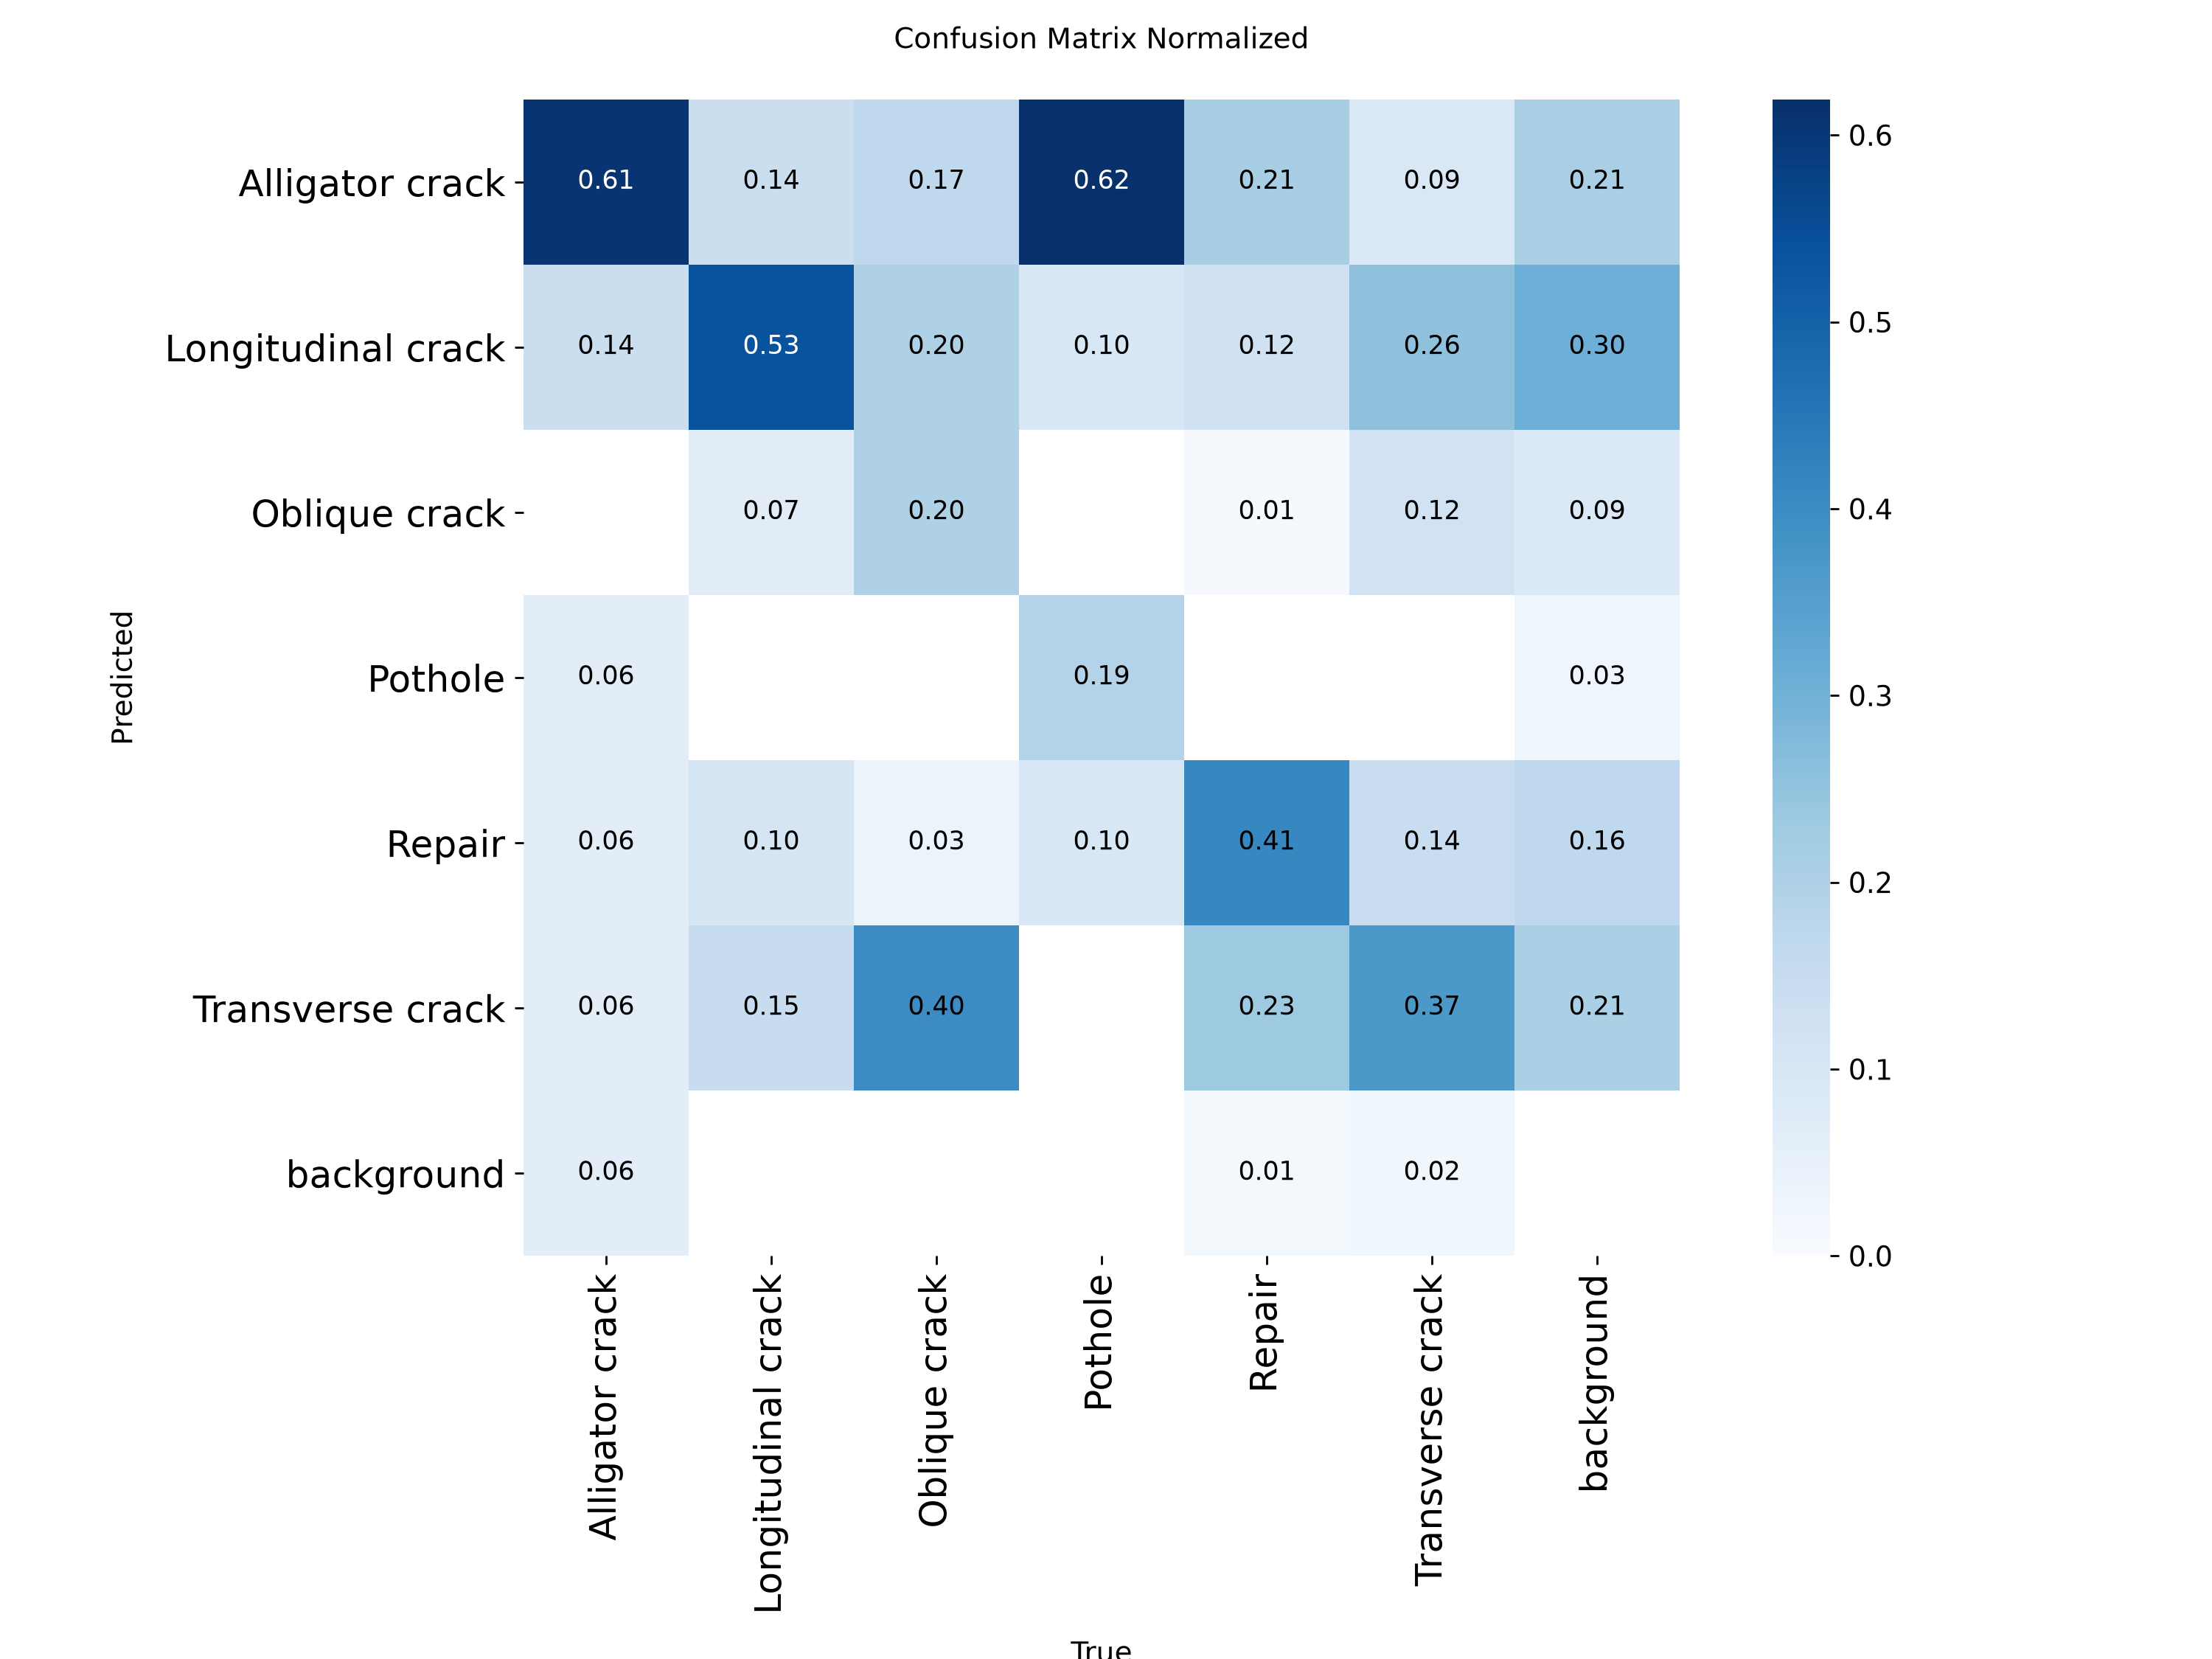

In [18]:
from pathlib import Path
from IPython.display import display, Image

results_folder = ARTIFACTS / "validation" / "fine_tuned"

matrix_path = results_folder / "confusion_matrix_normalized.png"

if matrix_path.exists():
    display(Image(filename=str(matrix_path)))
else:
    print("File not found:", matrix_path)

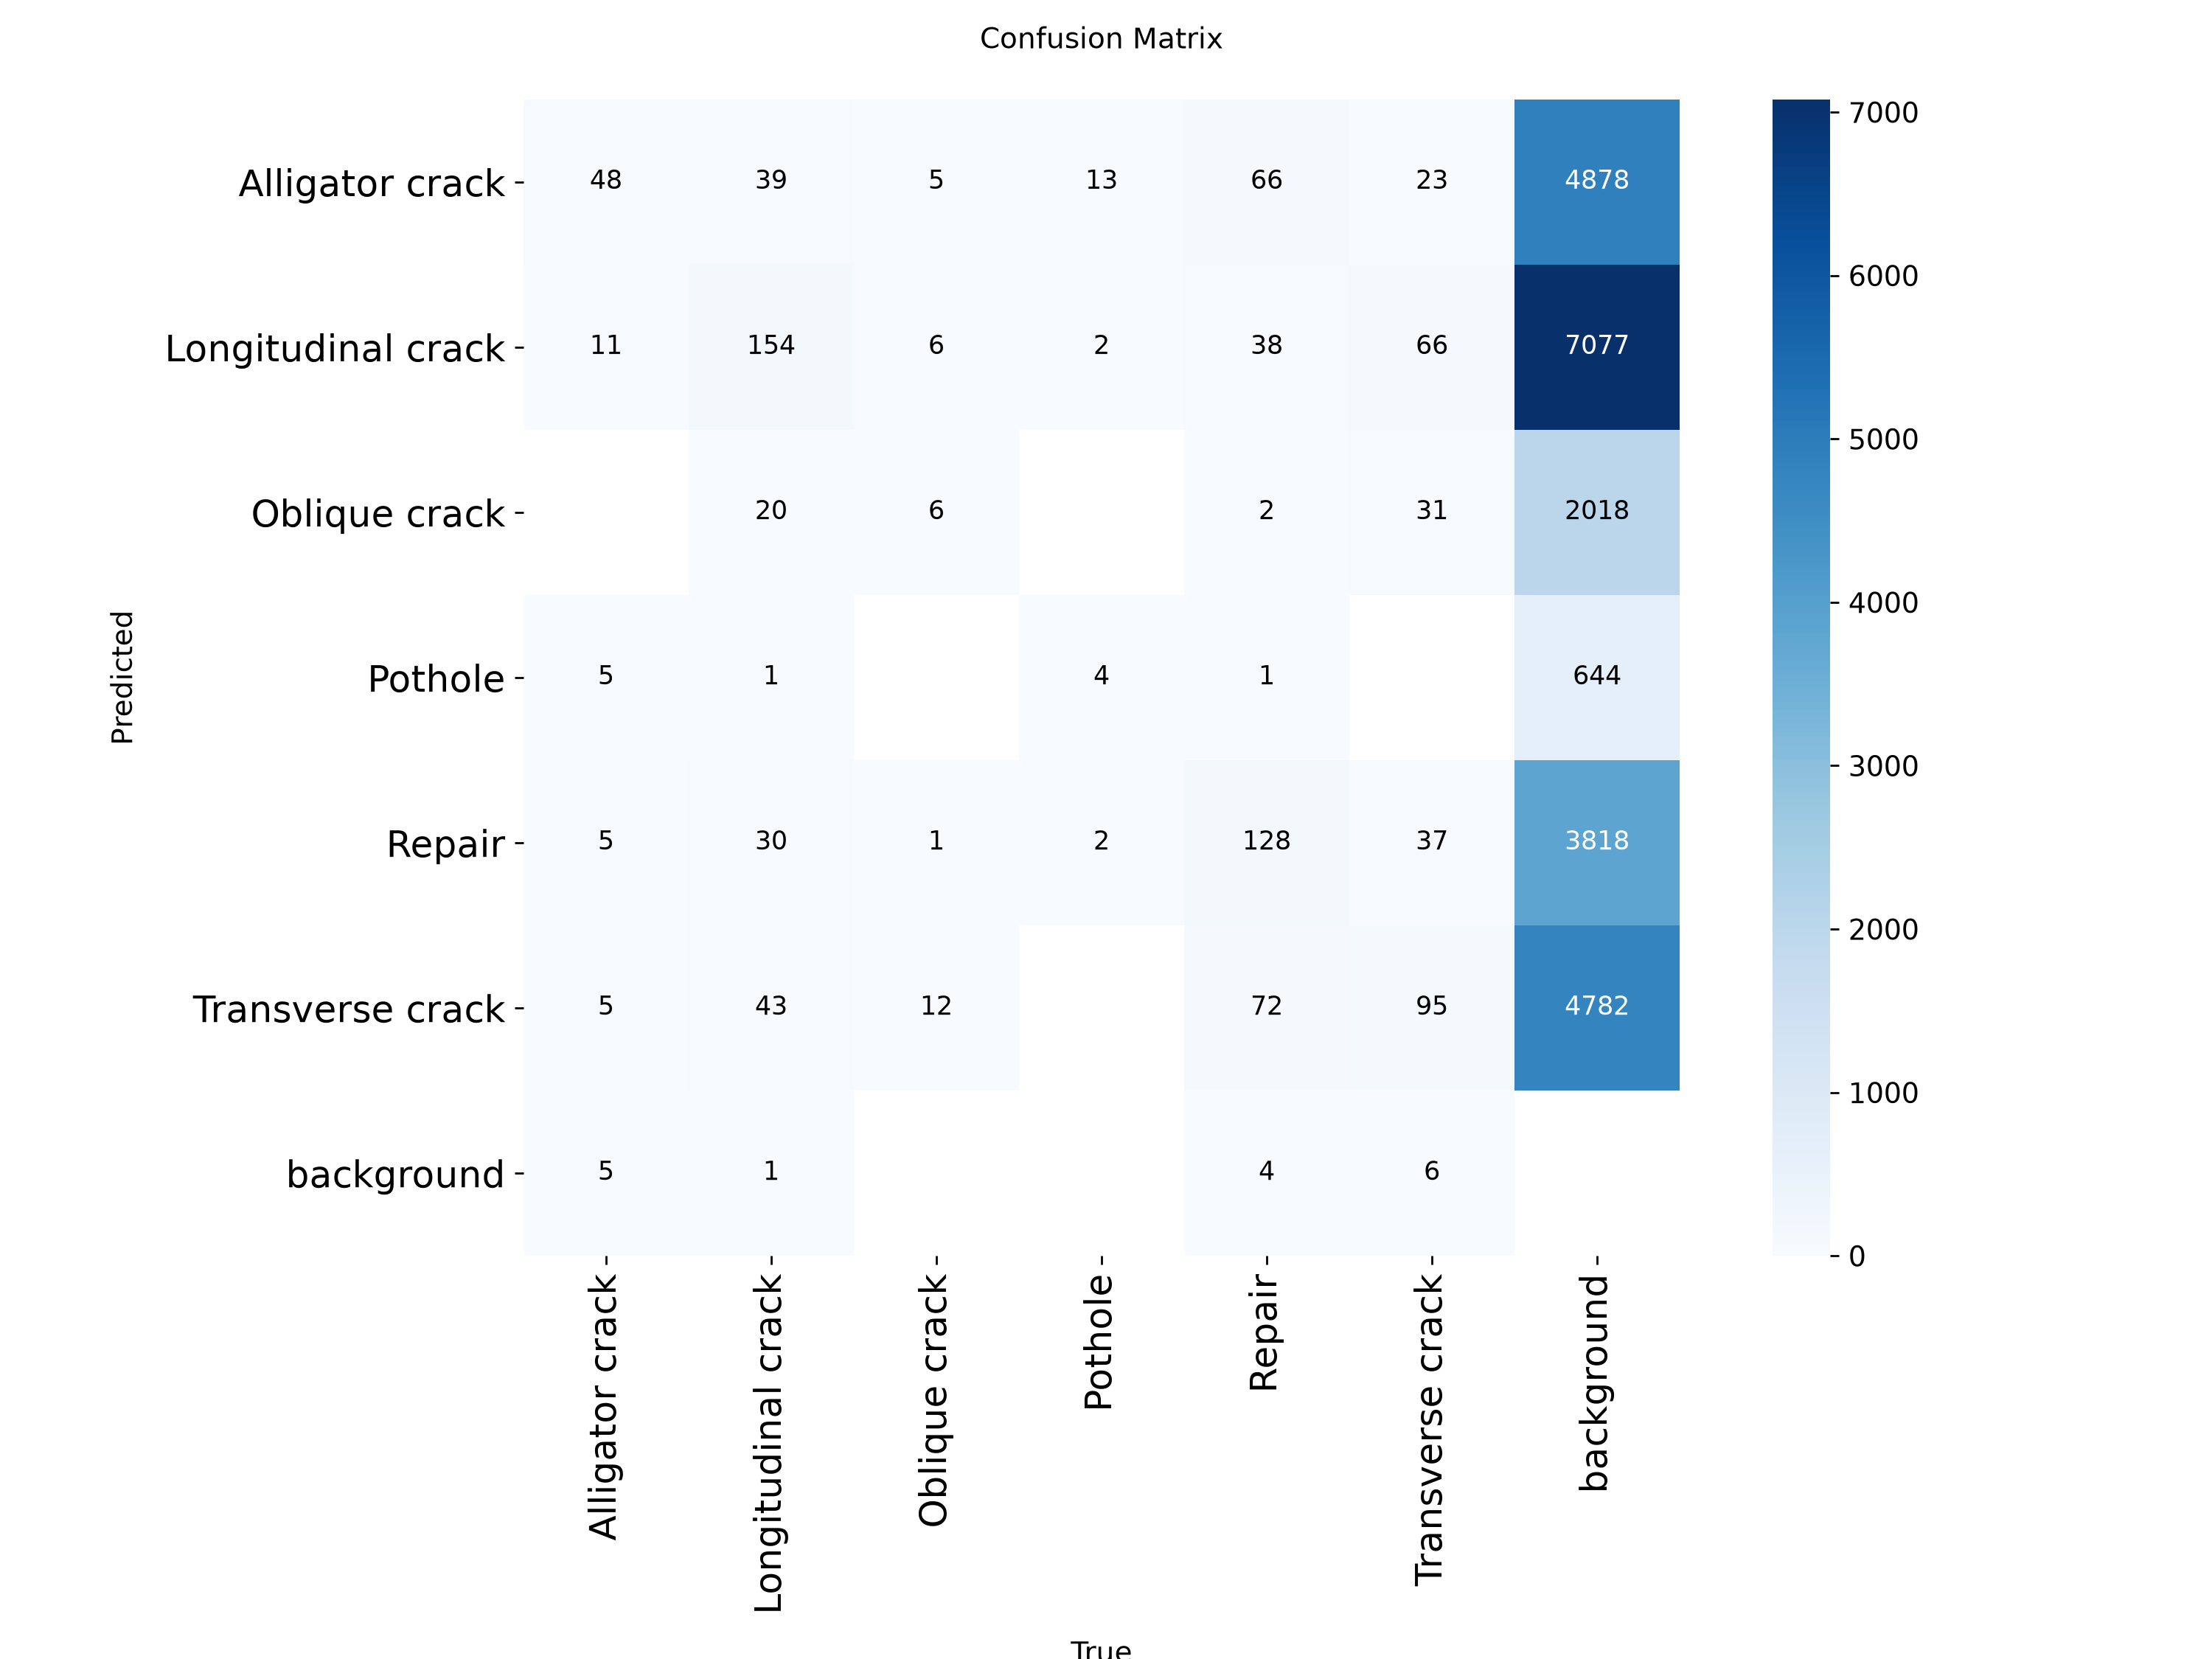

In [19]:
from IPython.display import display, Image

matrix_path = (
    ARTIFACTS
    / "validation"
    / "fine_tuned"
    / "confusion_matrix.png"
)

if matrix_path.exists():
    display(Image(filename=str(matrix_path)))
else:
    print("File not found:", matrix_path)

## 6. Business Cost Optimization

### Image-Level Predictions

I use the fine-tuned YOLO11n model to calculate a damage-confidence score for each validation image. This score will help determine whether an image should pass automatically, require human review, or be flagged for further inspection.

In [21]:
from pathlib import Path
from ultralytics import YOLO
import pandas as pd

VALID_IMAGES = DATA / "valid/images"
VALID_LABELS = DATA / "valid/labels"

output_path = ARTIFACTS / "validation_image_scores.csv"

ACTIVE_CLASSES = {0, 1, 2, 3, 5}

image_paths = sorted(
    p for p in VALID_IMAGES.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

# Reuse existing results only in saved-model mode
reuse_predictions = USE_SAVED_MODEL and output_path.exists()

if reuse_predictions:
    validation_scores = pd.read_csv(output_path)

    # Check that the saved CSV covers the current images
    expected_images = {p.name for p in image_paths}

    if (
        len(validation_scores) != len(image_paths)
        or set(validation_scores["image"]) != expected_images
    ):
        reuse_predictions = False

if reuse_predictions:
    print("Using existing Colab-model validation predictions.")

else:
    print("Generating fresh validation predictions.")

    prediction_model = YOLO(str(WEIGHTS / "best.pt"))
    records = []

    for i, image_path in enumerate(image_paths, start=1):

        prediction = prediction_model.predict(
            source=str(image_path),
            conf=0.01,
            imgsz=640,
            device="cpu",
            verbose=False
        )[0]

        # Ground-truth actionable damage
        label_path = VALID_LABELS / (image_path.stem + ".txt")

        actual_damage = 0

        if label_path.exists():
            for line in label_path.read_text().splitlines():
                if line.strip():
                    class_id = int(line.split()[0])

                    if class_id in ACTIVE_CLASSES:
                        actual_damage = 1

        # Highest actionable-damage confidence
        damage_score = 0.0

        for box in prediction.boxes:
            class_id = int(box.cls.item())

            if class_id in ACTIVE_CLASSES:
                damage_score = max(
                    damage_score,
                    float(box.conf.item())
                )

        records.append({
            "image": image_path.name,
            "actual_damage": actual_damage,
            "damage_score": damage_score
        })

        if i % 25 == 0:
            print(f"Processed {i} / {len(image_paths)}")

    validation_scores = pd.DataFrame(records)

    # Save only after the full evaluation finishes
    validation_scores.to_csv(output_path, index=False)

print("\nImages analyzed:", len(validation_scores))
print(
    "Images with active damage:",
    validation_scores["actual_damage"].sum()
)
print(
    "Images without active damage:",
    (validation_scores["actual_damage"] == 0).sum()
)

display(validation_scores.head(10))

Using existing Colab-model validation predictions.

Images analyzed: 628
Images with active damage: 438
Images without active damage: 190


,image,actual_damage,damage_score
0,0001_0_3_JPG.rf.ce7367821959cc16d14fdfd58075b1...,1,0.628529
1,0001_2_3_JPG.rf.3bcce815e1d1605f767f494ebdc5fc...,1,0.709391
2,0002_1_3_JPG.rf.e219cb939441473e7b9f8272551713...,1,0.579796
3,0002_2_5_JPG.rf.ef6a133813dadc3c789fcb08863883...,1,0.587416
4,0002_3_3_JPG.rf.7be6abbf77b1c47433618b7b1d343e...,1,0.507082
5,0002_4_3_JPG.rf.ccdc7951e4e4a01a246b2e21e8989d...,1,0.577271
6,0003_2_4_JPG.rf.8510bf6cd478cdaad746a169844d63...,1,0.785148
7,0003_4_2_JPG.rf.9a99f6f73106cb4805edae7941985c...,1,0.495501
8,0003_4_4_JPG.rf.db3d9f6db16488e60cd44bc9419a34...,1,0.729788
9,0003_5_2_JPG.rf.cef9e86b0da87f6526de563159eea6...,1,0.692841


### Cost Optimization — Confidence Threshold Sweep

I evaluate different confidence thresholds to identify the operating point that minimizes the estimated financial cost of missed damage and unnecessary inspections.

Best tested threshold: 0.05
Estimated cost: € 1675
False positives: 35
False negatives: 4

Pass everything: € 87600
Flag everything: € 4750


,threshold,TP,FP,TN,FN,total_cost
0,0.05,434,35,155,4,1675
1,0.10,429,22,168,9,2350
2,0.15,422,16,174,16,3600
3,0.20,413,12,178,25,5300
4,0.25,403,11,179,35,7275


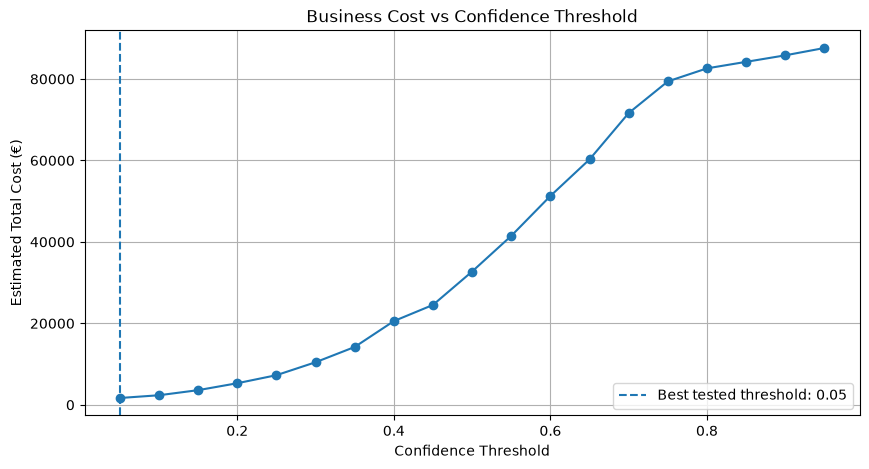

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Hypothetical business costs
COST_FN = 200  # Missed actionable damage
COST_FP = 25   # Unnecessary damage flag

actual = validation_scores["actual_damage"]
scores = validation_scores["damage_score"]

results = []

# Test confidence thresholds from 0.05 to 0.95
for threshold in np.arange(0.05, 1.00, 0.05):

    predicted = (scores >= threshold).astype(int)

    TP = int(((predicted == 1) & (actual == 1)).sum())
    FP = int(((predicted == 1) & (actual == 0)).sum())
    TN = int(((predicted == 0) & (actual == 0)).sum())
    FN = int(((predicted == 0) & (actual == 1)).sum())

    total_cost = FN * COST_FN + FP * COST_FP

    results.append({
        "threshold": round(float(threshold), 2),
        "TP": TP,
        "FP": FP,
        "TN": TN,
        "FN": FN,
        "total_cost": total_cost
    })

cost_results = pd.DataFrame(results)

# Lowest-cost threshold in our tested grid
best = cost_results.loc[
    cost_results["total_cost"].idxmin()
]

print("Best tested threshold:", best["threshold"])
print("Estimated cost: €", int(best["total_cost"]))
print("False positives:", int(best["FP"]))
print("False negatives:", int(best["FN"]))

# Simple alternatives
all_pass_cost = int(actual.sum()) * COST_FN
all_flag_cost = int((actual == 0).sum()) * COST_FP

print("\nPass everything: €", all_pass_cost)
print("Flag everything: €", all_flag_cost)

# Save results for the dashboard
cost_results.to_csv(
    ARTIFACTS / "cost_threshold_sweep.csv",
    index=False
)

display(cost_results.nsmallest(5, "total_cost"))

# Visualization
plt.figure(figsize=(10, 5))

plt.plot(
    cost_results["threshold"],
    cost_results["total_cost"],
    marker="o"
)

plt.axvline(
    best["threshold"],
    linestyle="--",
    label=f"Best tested threshold: {best['threshold']:.2f}"
)

plt.xlabel("Confidence Threshold")
plt.ylabel("Estimated Total Cost (€)")
plt.title("Business Cost vs Confidence Threshold")
plt.legend()
plt.grid(True)
plt.show()

### Human Review and Two-Threshold Optimization

In [23]:
import pandas as pd
import numpy as np

# Business costs
COST_FN = 200
COST_FP = 25
COST_REVIEW = 3

# Assumed daily staffing
DAILY_IMAGES = 1000
REVIEWERS = 2
HOURS_PER_REVIEWER = 6
MINUTES_PER_REVIEW = 3

daily_capacity = (
    REVIEWERS * HOURS_PER_REVIEWER * 60
    / MINUTES_PER_REVIEW
)

max_review_rate = daily_capacity / DAILY_IMAGES

print("Daily review capacity:", int(daily_capacity))
print("Maximum review rate:", f"{max_review_rate:.1%}")

# Reuse validation predictions from Step 16
actual = validation_scores["actual_damage"].to_numpy()
scores = validation_scores["damage_score"].to_numpy()

# Candidate thresholds
thresholds = sorted(set(
    [0.00, 0.01, 0.02, 0.03, 0.04]
    + list(np.round(np.arange(0.05, 1.01, 0.05), 2))
    + [1.01]
))

rows = []

for low in thresholds:
    for high in thresholds:

        if low > high:
            continue

        # Three possible decisions
        passed = scores < low
        reviewed = (scores >= low) & (scores < high)
        flagged = scores >= high

        # Business errors
        FN = int((passed & (actual == 1)).sum())
        FP = int((flagged & (actual == 0)).sum())
        N_review = int(reviewed.sum())

        total_cost = (
            FN * COST_FN
            + FP * COST_FP
            + N_review * COST_REVIEW
        )

        review_rate = N_review / len(scores)

        rows.append({
            "lower_threshold": low,
            "upper_threshold": high,
            "passed": int(passed.sum()),
            "reviewed": N_review,
            "flagged": int(flagged.sum()),
            "FN": FN,
            "FP": FP,
            "review_rate": review_rate,
            "total_cost": total_cost,
            "within_capacity": review_rate <= max_review_rate
        })

review_results = pd.DataFrame(rows)

# Consider only policies within staffing capacity
feasible = review_results[
    review_results["within_capacity"]
].copy()

best_policy = feasible.sort_values(
    ["total_cost", "reviewed"]
).iloc[0]

print("\nBEST FEASIBLE POLICY")
print(best_policy.to_string())

# Save for later analysis
review_results.to_csv(
    ARTIFACTS / "human_review_sweep.csv",
    index=False
)

print("\nTOP 10 FEASIBLE POLICIES")
display(feasible.nsmallest(10, "total_cost"))

Daily review capacity: 240
Maximum review rate: 24.0%

BEST FEASIBLE POLICY
lower_threshold        0.01
upper_threshold         0.2
passed                  117
reviewed                 86
flagged                 425
FN                        2
FP                       12
review_rate        0.136943
total_cost              958
within_capacity        True

TOP 10 FEASIBLE POLICIES


,lower_threshold,upper_threshold,passed,reviewed,flagged,FN,FP,review_rate,total_cost,within_capacity
33,0.01,0.20,117,86,425,2,12,0.136943,958,True
34,0.01,0.25,117,97,414,2,11,0.154459,966,True
35,0.01,0.30,117,114,397,2,10,0.181529,992,True
36,0.01,0.35,117,135,376,2,8,0.214968,1005,True
32,0.01,0.15,117,73,438,2,16,0.116242,1019,True
57,0.02,0.20,136,67,425,3,12,0.106688,1101,True
58,0.02,0.25,136,78,414,3,11,0.124204,1109,True
31,0.01,0.10,117,60,451,2,22,0.095541,1130,True
59,0.02,0.30,136,95,397,3,10,0.151274,1135,True
60,0.02,0.35,136,116,376,3,8,0.184713,1148,True


### Cost Sensitivity Analysis

I test how the optimal Pass / Review / Flag thresholds change under different business-cost assumptions, while maintaining the municipality's human-review capacity constraint.

In [24]:
import pandas as pd

# Different hypothetical business-cost scenarios
scenarios = [
    ("Original assumptions", 200, 25, 3),
    ("Cheaper missed damage", 100, 25, 3),
    ("More expensive missed damage", 400, 25, 3),
    ("More expensive false alarms", 200, 75, 3),
    ("More expensive human review", 200, 25, 6),
    ("Cheaper human review", 200, 25, 1)
]

sensitivity_rows = []

for name, cost_fn, cost_fp, cost_review in scenarios:

    comparison = feasible.copy()

    comparison["scenario_cost"] = (
        comparison["FN"] * cost_fn
        + comparison["FP"] * cost_fp
        + comparison["reviewed"] * cost_review
    )

    best = comparison.sort_values(
        ["scenario_cost", "reviewed"]
    ).iloc[0]

    sensitivity_rows.append({
        "scenario": name,
        "cost_fn": cost_fn,
        "cost_fp": cost_fp,
        "cost_review": cost_review,
        "lower_threshold": best["lower_threshold"],
        "upper_threshold": best["upper_threshold"],
        "passed": int(best["passed"]),
        "reviewed": int(best["reviewed"]),
        "flagged": int(best["flagged"]),
        "FN": int(best["FN"]),
        "FP": int(best["FP"]),
        "total_cost": int(best["scenario_cost"])
    })

sensitivity = pd.DataFrame(sensitivity_rows)

# Save results for the dashboard
sensitivity.to_csv(
    ARTIFACTS / "cost_sensitivity.csv",
    index=False
)

display(sensitivity)

,scenario,cost_fn,cost_fp,cost_review,lower_threshold,upper_threshold,passed,reviewed,flagged,FN,FP,total_cost
0,Original assumptions,200,25,3,0.01,0.20,117,86,425,2,12,958
1,Cheaper missed damage,100,25,3,0.01,0.20,117,86,425,2,12,758
2,More expensive missed damage,400,25,3,0.01,0.20,117,86,425,2,12,1358
3,More expensive false alarms,200,75,3,0.01,0.35,117,135,376,2,8,1405
4,More expensive human review,200,25,6,0.01,0.20,117,86,425,2,12,1216
5,Cheaper human review,200,25,1,0.01,0.35,117,135,376,2,8,735


In [25]:
import json

# Select the original business-cost scenario
selected = sensitivity.loc[
    sensitivity["scenario"] == "Original assumptions"
].iloc[0]

# Save the selected operating policy
policy = {
    "model_path": "weights/best.pt",
    "active_classes": [0, 1, 2, 3, 5],
    "excluded_class": 4,
    "inference_confidence_floor": 0.01,

    "lower_threshold": float(selected["lower_threshold"]),
    "upper_threshold": float(selected["upper_threshold"]),

    "costs_eur": {
        "false_negative": int(selected["cost_fn"]),
        "false_positive": int(selected["cost_fp"]),
        "human_review": int(selected["cost_review"])
    },

    "operations": {
        "daily_images": DAILY_IMAGES,
        "reviewers": REVIEWERS,
        "hours_per_reviewer": HOURS_PER_REVIEWER,
        "minutes_per_review": MINUTES_PER_REVIEW
    },

    "validation": {
        "passed": int(selected["passed"]),
        "reviewed": int(selected["reviewed"]),
        "flagged": int(selected["flagged"]),
        "false_negatives": int(selected["FN"]),
        "false_positives": int(selected["FP"]),
        "estimated_cost_eur": float(selected["total_cost"])
    }
}

# Save JSON for Gradio
policy_path = ARTIFACTS / "business_policy.json"

with open(policy_path, "w") as f:
    json.dump(policy, f, indent=4)

print("Business policy saved successfully!")
print("\nSelected thresholds:")
print("Pass threshold:", policy["lower_threshold"])
print("Flag threshold:", policy["upper_threshold"])

print("\nBusiness assumptions:")
print(policy["costs_eur"])

print("\nValidation results:")
print(policy["validation"])

Business policy saved successfully!

Selected thresholds:
Pass threshold: 0.01
Flag threshold: 0.2

Business assumptions:
{'false_negative': 200, 'false_positive': 25, 'human_review': 3}

Validation results:
{'passed': 117, 'reviewed': 86, 'flagged': 425, 'false_negatives': 2, 'false_positives': 12, 'estimated_cost_eur': 958.0}


## 7. Final Test Evaluation

The model and business thresholds were selected using validation data. I now evaluate the fixed policy on the test set without further optimization.

In [26]:
from pathlib import Path
from ultralytics import YOLO
import pandas as pd

TEST_IMAGES = DATA / "test/images"
TEST_LABELS = DATA / "test/labels"

output_path = ARTIFACTS / "test_image_scores.csv"

# Use the business policy selected on validation data
active_classes = set(policy["active_classes"])
lower = policy["lower_threshold"]
upper = policy["upper_threshold"]
confidence_floor = policy["inference_confidence_floor"]

image_paths = sorted(
    p for p in TEST_IMAGES.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

# Reuse existing predictions only in saved-model mode
reuse_predictions = USE_SAVED_MODEL and output_path.exists()

if reuse_predictions:
    test_df = pd.read_csv(output_path)

    expected_images = {p.name for p in image_paths}

    if (
        len(test_df) != len(image_paths)
        or set(test_df["image"]) != expected_images
        or not {"actual_damage", "damage_score"}.issubset(test_df.columns)
    ):
        reuse_predictions = False

if reuse_predictions:
    print("Using existing Colab-model test predictions.")

else:
    print("Generating fresh test predictions.")

    test_model = YOLO(str(WEIGHTS / "best.pt"))
    records = []

    for i, image_path in enumerate(image_paths, start=1):

        prediction = test_model.predict(
            source=str(image_path),
            conf=confidence_floor,
            imgsz=640,
            device="cpu",
            verbose=False
        )[0]

        label_path = TEST_LABELS / (image_path.stem + ".txt")

        if not label_path.exists():
            raise FileNotFoundError(label_path)

        actual_damage = 0

        for line in label_path.read_text().splitlines():
            if line.strip():
                class_id = int(line.split()[0])

                if class_id in active_classes:
                    actual_damage = 1

        damage_score = 0.0

        for box in prediction.boxes:
            class_id = int(box.cls.item())

            if class_id in active_classes:
                damage_score = max(
                    damage_score,
                    float(box.conf.item())
                )

        records.append({
            "image": image_path.name,
            "actual_damage": actual_damage,
            "damage_score": damage_score
        })

        if i % 25 == 0:
            print(f"Processed {i} / {len(image_paths)}")

    test_df = pd.DataFrame(records)

# Apply the fixed validation-selected thresholds
def classify_image(score):
    if score < lower:
        return "Pass"
    elif score < upper:
        return "Review"
    else:
        return "Flag"

test_df["decision"] = test_df["damage_score"].apply(
    classify_image
)

# Save results
test_df.to_csv(output_path, index=False)

print("\nFINAL TEST RESULTS")
print("Images:", len(test_df))
print("Active damage:", test_df["actual_damage"].sum())

print("\nDecisions:")
print(test_df["decision"].value_counts())

Using existing Colab-model test predictions.

FINAL TEST RESULTS
Images: 316
Active damage: 216

Decisions:
decision
Flag      211
Pass       58
Review     47
Name: count, dtype: int64


In [27]:
import pandas as pd

# Costs selected during validation
COST_FN = policy["costs_eur"]["false_negative"]
COST_FP = policy["costs_eur"]["false_positive"]
COST_REVIEW = policy["costs_eur"]["human_review"]

actual = test_df["actual_damage"]
decisions = test_df["decision"]
scores = test_df["damage_score"]

# Hybrid policy errors
FN = int(((decisions == "Pass") & (actual == 1)).sum())
FP = int(((decisions == "Flag") & (actual == 0)).sum())
reviewed = int((decisions == "Review").sum())

hybrid_cost = (
    FN * COST_FN
    + FP * COST_FP
    + reviewed * COST_REVIEW
)

# Alternative strategies
all_pass_cost = int(actual.sum()) * COST_FN

all_flag_cost = int((actual == 0).sum()) * COST_FP

all_review_cost = len(test_df) * COST_REVIEW

# Fully automated YOLO using the threshold
# previously selected on validation data
auto_threshold = float(
    cost_results.loc[
        cost_results["total_cost"].idxmin(),
        "threshold"
    ]
)

auto_flag = scores >= auto_threshold

auto_FN = int(((~auto_flag) & (actual == 1)).sum())
auto_FP = int((auto_flag & (actual == 0)).sum())

auto_cost = auto_FN * COST_FN + auto_FP * COST_FP

# Compare strategies
comparison = pd.DataFrame({
    "Strategy": [
        "Pass everything",
        "Flag everything",
        "Review everything",
        "Fully automated YOLO",
        "Hybrid YOLO + human review"
    ],
    "Estimated cost (€)": [
        all_pass_cost,
        all_flag_cost,
        all_review_cost,
        auto_cost,
        hybrid_cost
    ]
})

print("FINAL TEST BUSINESS RESULTS")
print("Missed damage:", FN)
print("Unnecessary flags:", FP)
print("Human reviews:", reviewed)
print("Review rate:", f"{reviewed / len(test_df):.1%}")
print("Automated YOLO threshold:", auto_threshold)

print("\nEstimated hybrid cost: €", hybrid_cost)

display(comparison)

comparison.to_csv(
    ARTIFACTS / "test_business_comparison.csv",
    index=False
)

FINAL TEST BUSINESS RESULTS
Missed damage: 1
Unnecessary flags: 8
Human reviews: 47
Review rate: 14.9%
Automated YOLO threshold: 0.05

Estimated hybrid cost: € 541


,Strategy,Estimated cost (€)
0,Pass everything,43200
1,Flag everything,2500
2,Review everything,948
3,Fully automated YOLO,900
4,Hybrid YOLO + human review,541


In [28]:
from ultralytics import YOLO
import pandas as pd

metrics_path = ARTIFACTS / "test_detection_metrics.csv"

# Reuse existing metrics only in saved-model mode
if USE_SAVED_MODEL and metrics_path.exists():

    print("Using existing test detection metrics.")

    per_class_test = pd.read_csv(metrics_path)

    required_columns = {
        "class", "precision", "recall", "mAP50", "mAP50-95"
    }

    if not required_columns.issubset(per_class_test.columns):
        raise ValueError("Saved test metrics have missing columns.")

    overall_map50 = per_class_test["mAP50"].mean()
    overall_map5095 = per_class_test["mAP50-95"].mean()

else:

    print("Evaluating the trained model on the test set.")

    model = YOLO(str(WEIGHTS / "best.pt"))

    test_metrics = model.val(
        data=str(EVAL_YAML.resolve()),
        split="test",
        imgsz=640,
        batch=8,
        device="cpu",
        plots=True,
        project=str(ARTIFACTS / "test_detection"),
        name="final",
        exist_ok=True
    )

    rows = []

    for i, class_id in enumerate(test_metrics.box.ap_class_index):

        precision, recall, ap50, ap5095 = (
            test_metrics.class_result(i)
        )

        rows.append({
            "class": model.names[int(class_id)],
            "precision": round(float(precision), 4),
            "recall": round(float(recall), 4),
            "mAP50": round(float(ap50), 4),
            "mAP50-95": round(float(ap5095), 4)
        })

    per_class_test = pd.DataFrame(rows)

    overall_map50 = test_metrics.box.map50
    overall_map5095 = test_metrics.box.map

    per_class_test.to_csv(metrics_path, index=False)

print("\nFINAL TEST DETECTION RESULTS")

display(per_class_test)

print("Overall test mAP50:", round(overall_map50, 4))
print("Overall test mAP50-95:", round(overall_map5095, 4))

Using existing test detection metrics.

FINAL TEST DETECTION RESULTS


,class,precision,recall,mAP50,mAP50-95
0,Alligator crack,0.7718,0.4737,0.5929,0.3378
1,Longitudinal crack,0.7262,0.6441,0.7101,0.3495
2,Oblique crack,0.5830,0.4167,0.3852,0.2919
3,Pothole,0.9781,0.5000,0.6196,0.3465
4,Repair,0.7225,0.8701,0.8569,0.6366
5,Transverse crack,0.7368,0.6867,0.7482,0.4337


Overall test mAP50: 0.6521
Overall test mAP50-95: 0.3993
